# Lista 1 – ICs e Bootstrap

## Intervalos de Confiança

Intervalos de confiança são intervalos calculados a partir de observações que podem variar de amostra para amostra e que com dada frequência (nível de confiança) incluem o parâmetro de interesse real não observável.

**Por exemplo:** Um intervalo com nível de confiança de 99% para a média de uma variável aleatória significa que ao calcularmos *n* intervalos de confiança tomando como base *n* amostras aleatórias, espera-se que 99% dos intervalos construídos contenham o valor real do parâmetro (média).

Em outras palavras, o nível de confiança seria a proporção de intervalos de confiança construídos em experimentos separados da mesma população e com o mesmo procedimento que contêm o parâmetro de interesse real.

Foram ministradas duas maneiras de construirmos intervalos de confiança:

- Probabilisticamente direto dos dados (Forma clássica).
- Via reamostragem com reposição (*Bootstrap*).

Para o primeiro caso, lembrando do conceito visto em aula, temos (para um IC com 95% de confiança):

$$\begin{align}
0.95 = P(-z \le Z \le z)=P \left(-1.96 \le \frac {\bar X-\mu}{\sigma/\sqrt{n}} \le 1.96 \right) = P \left( \bar X - 1.96 \frac \sigma {\sqrt{n}} \le \mu \le \bar X + 1.96 \frac \sigma {\sqrt{n}}\right).
\end{align}$$

Vamos colocar na prática!

In [32]:
## Imports para essa lista :)
import matplotlib.pyplot as plt

import numpy as np
import seaborn as sns
import scipy.stats as ss


np.random.seed(30091985)

plt.rcParams["figure.figsize"] = (10, 8)
plt.ion();

## Exemplo Inicial

Vamos começar construindo um intervalo de confiança para a média de uma distribuição Normal (Gaussiana) com média $\mu = 0$ e variância $\sigma² = 1$.

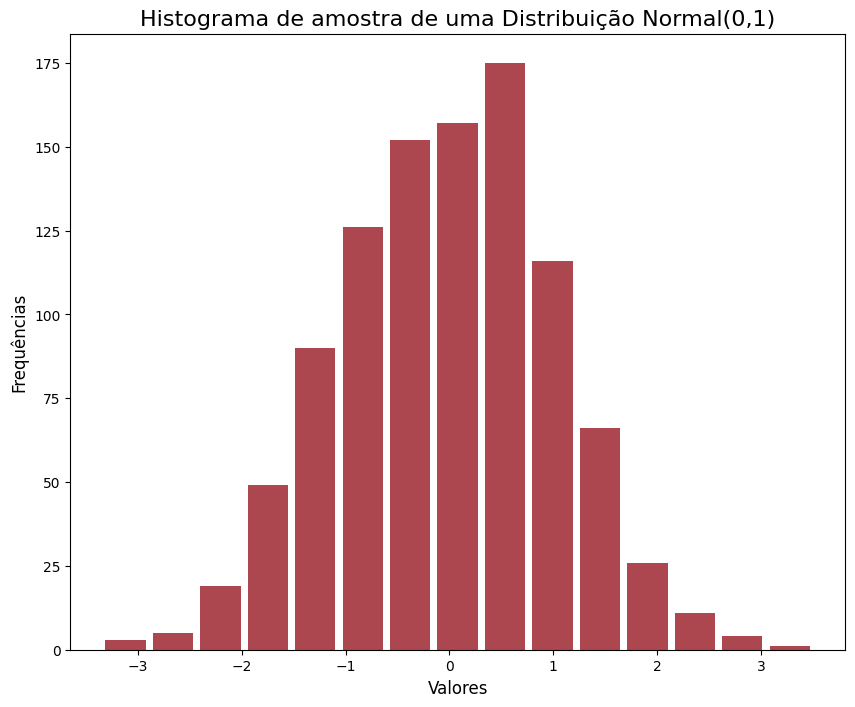

INTERVALO DE CONFIANCA (manual) = [-0.0833, 0.0439]
INTERVALO DE CONFIANCA (com scipy)= [-0.0833, 0.0439]


In [33]:
def confidence_interval(loc, scale, alpha=0.99):
    """
    Essa função cria uma distribuição Normal com base nos
    parâmetros fornecidos e constrói um intervalo de confiança para sua média.

    Parameters:
    -----------
    loc (float): Média da distribuição desejada.
    scale (float): Desvio padrão da distribuição desejada.
    alpha (float): Nível de confiança do intervalo. Deve ser um valor entre 0 e 1. Default = 0.99, o que corresponde a 99% de confiança.

    Returns:
    -----------
    X (array): Dados gerados segundo uma distribuição Normal(0,1).
    LI (float): Limite inferior do intervalo calculado.
    LS (float): Limite superior do intervalo calculado.

    """

    # Gerando amostra de uma Normal(média,std) de tamanho N
    N = 1000
    X = np.random.normal(loc=loc, scale=scale, size=N)

    # Criando plot da amostra gerada
    plt.xlabel('Valores', fontsize=12)
    plt.ylabel('Frequências', fontsize=12)
    plt.title('Histograma de amostra de uma Distribuição Normal(0,1)', fontsize=16)

    plt.hist(X, color='#A3333D', alpha=0.9, rwidth=0.85, bins=15)
    plt.show()

    # Calculando intervalo de  95% de confiança para a média manualmente
    LI = X.mean() - 1.96 * (X.std(ddof=1) / np.sqrt(N)) # LI = limite inferior
    LS = X.mean() + 1.96 * (X.std(ddof=1) / np.sqrt(N)) # LS = limite superior
    print("INTERVALO DE CONFIANCA (manual) = [{:.4f}, {:.4f}]".format(LI, LS))

    # Utilizando o valor da confiança como base, utilizamos o pacote scipy.stats
    LI = X.mean() - ss.norm.ppf(alpha+(1-alpha)/2).round(2) * (X.std(ddof=1) / np.sqrt(N))
    LS = X.mean() + ss.norm.ppf(alpha+(1-alpha)/2).round(2) * (X.std(ddof=1) / np.sqrt(N))

    # Printando intervalo de confiança
    print("INTERVALO DE CONFIANCA (com scipy)= [{:.4f}, {:.4f}]".format(LI, LS))

    return X, LI, LS

X, LI, LS = confidence_interval(loc=0, scale=1, alpha=0.95)

Podemos afirmar que, se repetirmos muitas vezes o experimento, coletando novas amostras e construindo novos intervalos, aproximadamente 95% dos intervalos construídos conterão a média populacional.

**Algumas observações interessantes. Note que:**
- A cada vez que executamos o código acima, tanto os intervalos como o histograma dos dados são diferentes. Estamos realizando uma amostra de uma distribuição.
- A medida que o tamanho da amostra (N) cresce, o tamanho do intervalo - para um mesmo nível de confiança - cai. Isso ocorre pois, o aumento do tamanho amostral reduz o erro padrão da média, resultando em intervalos de confiança mais estreitos.
- Os valores dos intervalos de confiança (manual e scipy) só coincidem quando *alpha=0.95*. Essa é a vantagem de se utilizar o pacote. Para valores diferentes de 0.95, deve-se consultar o valor correspondente na distribuição Z.

## Dados ENEM 2015.

Nos exercícios dessa seção vamos trabalhar com os dados do [ENEM 2015](https://raw.githubusercontent.com/pedroharaujo/ICD_Docencia/master/enem2015.csv).

Importando pandas e carregando dados.

In [2]:
import pandas as pd

url = 'https://github.com/icd-ufmg/icd-ufmg.github.io/raw/master/listas/l4/enem2015.csv'
data = pd.read_csv(url)

Primeiras visualizações do banco de dados do ENEM 2015.

In [3]:
data.head()

,DEPENDENCIA_ADMINISTRATIVA,NOTA_MEDIA_ESCOLA,TAXA_DE_APROVACAO,TAXA_DE_PARTICIPACAO
0,Federal,659.258362,92.2,96.894409
1,Federal,637.646728,86.5,98.717949
2,Estadual,556.710632,82.5,74.603180
3,Estadual,542.865967,70.2,54.651165
4,Estadual,557.379150,67.0,64.864861


In [4]:
data.describe()

,NOTA_MEDIA_ESCOLA,TAXA_DE_APROVACAO,TAXA_DE_PARTICIPACAO
count,1685.000000,1683.000000,1685.000000
mean,575.391745,86.044444,75.263669
std,40.796223,10.334011,16.886193
min,487.007141,47.700000,50.000000
25%,544.937500,79.500000,59.615387
50%,561.520752,87.800000,72.916672
75%,607.530579,94.550000,92.857140
max,713.629028,100.000000,100.000000


## Exercício 01

Altere a função abaixo para retornar o intervalo de confiança para a média da variável 'NOTA_MEDIA_ESCOLA' para escolas com 'DEPENDENCIA_ADMINISTRATIVA' == Estadual.

Nível de confiança: 99%

**Lembrete**: será necessário aplicar os conhecimentos de pandas do módulo anterior para filtrar o DataFrame selecionando apenas os casos de interesse.

In [17]:
import numpy as np
import scipy.stats as ss

def CI(data):

  estaduais = data.loc[
      data["DEPENDENCIA_ADMINISTRATIVA"] == "Estadual","NOTA_MEDIA_ESCOLA"
      ].dropna()

  n = len(estaduais)
  media = estaduais.mean()
  dp = estaduais.std(ddof=1)

  z = ss.norm.ppf(0.995)
  erro = z * dp / np.sqrt(n)

  LI = media - erro
  LS = media + erro

  return LI, LS

LI, LS = CI(data)
print(f"IC de 99%: [{LI:.2f}, {LS:.2f}]")

# array = pegue os dados
# CI(data)

IC de 99%: [548.13, 551.09]


Carregando os módulos de testes!

In [18]:
from numpy.testing import assert_almost_equal
from numpy.testing import assert_equal

from numpy.testing import assert_array_almost_equal
from numpy.testing import assert_array_equal

Nosso teste

In [34]:
(LI, LS) = CI(data)

assert_equal(548.13, round(LI,2))
assert_equal(551.09, round(LS,2))

print(assert_equal(548.13, round(LI,2))) #ah, não retorna é nada, só verifica msm

None


## Exercício 02 (Sem correção automática)

Plote uma CDF da coluna 'TAXA_DE_APROVACAO'.

**Use o statsmodels e crie um objeto `ecdf = ECDF(...)`.**


Esta tarefa não tem correção automática, use o gráfico abaixo para saber se acertou ou não.

![](https://github.com/pedroharaujo/ICD_Docencia/blob/master/ECDF.png?raw=true)

In [9]:
# código para importar a função ECDF
from statsmodels.distributions.empirical_distribution import ECDF

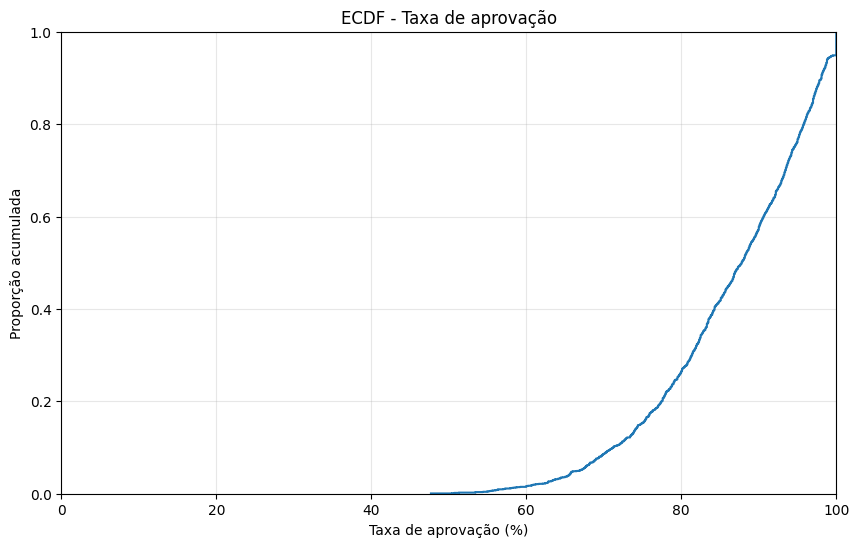

In [38]:
# YOUR CODE HERE
aprovacao = data["TAXA_DE_APROVACAO"].dropna()
ecdf = ECDF(aprovacao)

plt.figure(figsize=(10, 6))
plt.step(ecdf.x[1:], ecdf.y[1:], where="post")

plt.xlabel("Taxa de aprovação (%)")
plt.ylabel("Proporção acumulada")
plt.title("ECDF - Taxa de aprovação")
plt.xlim(0, 100)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

## Bootstrap

Quando falamos em Bootstrap, deve-se ter em mente que estamos falando de reamostragem com reposição.

De maneira simplificada, utilizamos Bootstrap quando queremos estimar a variabilidade de uma estatística, como a média, e construir intervalos de confiança a partir dos dados disponíveis. Ao realizarmos várias reamostragens **com reposição**, podemos aproximar a distribuição amostral dessa estatística sem precisar conhecer a distribuição da população.

Note o destaque para o termo **com reposição**. É CRUCIAL que as reamostragens sejam feitas com reposição, permitindo que uma mesma observação seja selecionada mais de uma vez. Entretanto, o Bootstrap não corrige possíveis problemas de representatividade da amostra original.

Veja o exemplo abaixo.

In [ ]:
col = 'TAXA_DE_PARTICIPACAO'
n_sub = 10000 #numero de sub-amostras
size = len(data) #tamanho do dataframe

def bootstrap(n_sub, size, col):
  values = np.zeros(n_sub)
  for i in range(n_sub):
      sample = data.sample(size, replace=True)

      # Lembre que podemos utilizar mediana, média ou qualquer outra estatística agregada
      # values[i] = sample[col].median()
      values[i] = sample[col].mean()

  # Gerando valores inferior e superior para um nível de confiança de 95%
  LI = np.percentile(values, 2.5)
  LS = np.percentile(values, 97.5)
  return values, LI, LS

values, LI, LS = bootstrap(n_sub, size, col)
print('Intervalo de Confianca: [{}, {}]'.format(LI.round(4), LS.round(4)))

## Exercício 03

Realizando um groupby pela coluna 'DEPENDENCIA_ADMINISTRATIVA', conseguimos observar a quantidade de observações em cada grupo, informação importante para avaliar a confiabilidade das estimativas estatísticas.

In [39]:
data.groupby('DEPENDENCIA_ADMINISTRATIVA').count()

,NOTA_MEDIA_ESCOLA,TAXA_DE_APROVACAO,TAXA_DE_PARTICIPACAO
DEPENDENCIA_ADMINISTRATIVA,,,
Estadual,1054,1054,1054
Federal,43,42,43
Municipal,22,22,22
Privada,566,565,566


**A)** O tamanho da amostra é um fator importante para a confiabilidade dos intervalos de confiança, inclusive aqueles construídos por Bootstrap. Amostras pequenas podem apresentar maior incerteza nas estimativas e exigir maior cautela na interpretação dos resultados.  

Na função abaixo, retorne o número da opção que indica quais categorias de 'DEPENDENCIA_ADMINISTRATIVA' apresentam as menores quantidades de observações.

1. Estadual e Federal.
2. Estadual e Municipal.
3. Estadual e Privada.
4. Federal e Municipal.
5. Federal e Privada.
6. Municipal e Privada.

In [54]:
def resposta():
    # Escolha uma das opções acima
    # return 1 ou 2 ou 3 ou 4 ou 5 ou 6
    # Escreva sua resposta abaixo:
    # YOUR CODE HERE
    return 4

**B)** No exercício anterior, identificamos as categorias com menor quantidade de observações. Embora o Bootstrap possa ser aplicado a essas amostras, ele não elimina as limitações decorrentes do tamanho amostral.

Como exercício prático, construa um intervalo de confiança via Bootstrap para a média da variável 'NOTA_MEDIA_ESCOLA' das escolas de 'DEPENDENCIA_ADMINISTRATIVA' **Federal**. Utilize 5000 reamostragens com reposição, cada uma com o mesmo tamanho da amostra original de escolas federais, e um nível de confiança de 90%.

In [55]:
federais = data.query('DEPENDENCIA_ADMINISTRATIVA == "Federal"')

for i in range(5000):
    d_novo = federais.sample(n=len(federais), replace=True)
    d_novo.NOTA_MEDIA_ESCOLA.mean()

In [62]:
def bootstrap_mean(n_sub, alpha):
  notas = federais["NOTA_MEDIA_ESCOLA"].dropna().to_numpy()
  n = len(notas)

  np.random.seed(30091985)

  indice = np.random.randint(0, n, size=(n_sub, n))
  values = notas[indice].mean(axis=1)

  cauda = (1 - alpha) / 2

  LI = np.percentile(values, 100 * cauda)
  LS = np.percentile(values, 100 * (1 - cauda))

  return values, (LI, LS)

In [66]:
values, (LI, LS) = bootstrap_mean(n_sub=5000, alpha=0.9)
assert round(LI) in (620, 621, 622)
assert round(LS) in (634, 635, 636)

**C)** No item anterior, utilizamos Bootstrap para construir um intervalo de confiança para a média das notas das escolas federais, que possuem uma quantidade relativamente pequena de observações.

A utilização de 5000 reamostragens garante que o intervalo obtido seja confiável, mesmo com uma amostra original pequena? Justifique brevemente.

**Resposta:** Não garante, porque uma amostra original pequena apresenta limitações que o boostrap não consegue superar mesmo reduzindo a variablidade com 5000 amostras, isso acontece porque ele reutilzia os dados sem acrescentar novos